In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn import svm
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score

In [ ]:
heart_data = pd.read_csv('/content/Heart_Disease_Prediction.csv')

In [ ]:
heart_data

,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,Presence
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,Absence
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,Presence
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,Absence
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,Absence
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
265,52,1,3,172,199,1,0,162,0,0.5,1,0,7,Absence
266,44,1,2,120,263,0,0,173,0,0.0,1,0,7,Absence
267,56,0,2,140,294,0,2,153,0,1.3,2,0,3,Absence
268,57,1,4,140,192,0,0,148,0,0.4,2,0,6,Absence


In [ ]:
heart_data.shape

(270, 14)

In [ ]:
heart_data.isnull().sum().sum()

np.int64(0)

In [ ]:
# Returns a single number (total count)
heart_data.duplicated().sum()


np.int64(0)

In [ ]:
heart_data.groupby('Heart Disease')['Heart Disease'].count()

,Heart Disease
Heart Disease,
Absence,150
Presence,120


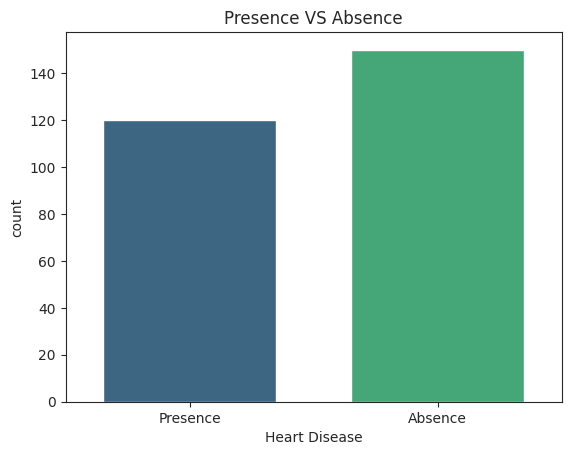

In [ ]:
sns.set_style('ticks')
sns.countplot(data = heart_data, x ='Heart Disease', width = 0.7, palette = 'viridis', hue = 'Heart Disease')
plt.title('Presence VS Absence')
plt.show()

In [ ]:
mapping = {'Presence': 1, 'Absence': 0}
heart_data['Heart Disease'] = heart_data['Heart Disease'].map(mapping)

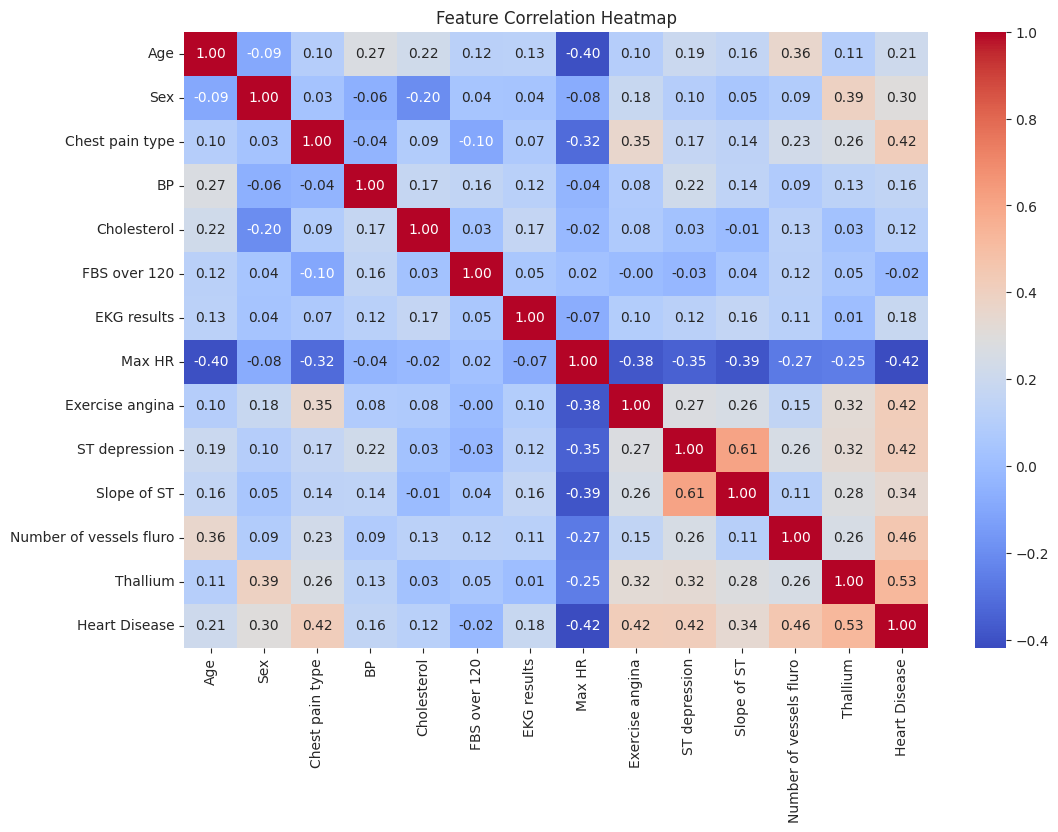

In [ ]:
plt.figure(figsize=(12,8))
sns.heatmap(heart_data.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation Heatmap')
plt.show()

As you can see above there are no missing values or duplicates and according to the chart absence is more than presence but not by much so the dataset isnt imbalanced but just to be safe i will make them equal


In [ ]:
heart_data

,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,1
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,0
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,1
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,0
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
265,52,1,3,172,199,1,0,162,0,0.5,1,0,7,0
266,44,1,2,120,263,0,0,173,0,0.0,1,0,7,0
267,56,0,2,140,294,0,2,153,0,1.3,2,0,3,0
268,57,1,4,140,192,0,0,148,0,0.4,2,0,6,0


In [ ]:
from imblearn.over_sampling import SMOTENC

In [ ]:
X_initial = heart_data.drop('Heart Disease', axis=1)
y_initial = heart_data['Heart Disease']

In [ ]:
cat_indices = [1, 2, 5, 6, 8, 10, 11, 12]
smote = SMOTENC(categorical_features=cat_indices, random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_initial, y_initial)

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [ ]:
selected_columns = [
    'Age', 'Sex', 'Chest pain type', 'Max HR',
    'Exercise angina', 'ST depression', 'Slope of ST',
    'Number of vessels fluro', 'Thallium'
    ]
X_selected = X_resampled[selected_columns]

X_dummy = pd.get_dummies(X_selected, drop_first=True)

scaler_pca = StandardScaler()
X_scaled_for_pca = scaler_pca.fit_transform(X_dummy)

pca = PCA(n_components=0.95)
X_pca = pca.fit_transform(X_scaled_for_pca)

print(f"Features reduced from {X_dummy.shape[1]} to {pca.n_components_} components.")

Features reduced from 9 to 8 components.


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_pca, y_resampled, test_size=0.2, random_state=42)

In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
y_train = y_train.astype('int')
y_test = y_test.astype('int')

In [ ]:
lr_model = LogisticRegression()
lr_model.fit(X_train, y_train)

LogisticRegression()

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_auc_score, roc_curve, ConfusionMatrixDisplay)

In [ ]:
y_train_pred_lr = lr_model.predict(X_train)
y_test_pred_lr = lr_model.predict(X_test)
y_test_prob_lr = lr_model.predict_proba(X_test)[:, 1]
y_train_prob_lr = lr_model.predict_proba(X_train)[:, 1]

print("\n--- Logistic Regression Metrics (Test) ---")
print(f"Accuracy: {accuracy_score(y_test, y_test_pred_lr):.4f}")
print(f"Precision: {precision_score(y_test, y_test_pred_lr):.4f}")
print(f"Recall: {recall_score(y_test, y_test_pred_lr):.4f}")
print(f"F1 Score: {f1_score(y_test, y_test_pred_lr):.4f}")
print(f"AUC-ROC: {roc_auc_score(y_test, y_test_prob_lr):.4f}")


--- Logistic Regression Metrics (Test) ---
Accuracy: 0.8667
Precision: 0.8000
Recall: 0.9655
F1 Score: 0.8750
AUC-ROC: 0.9633


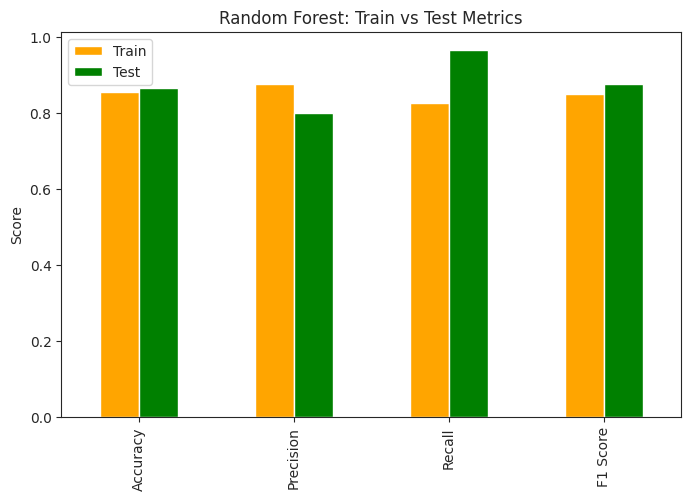

In [ ]:
metrics_lr = {
    'Accuracy': [accuracy_score(y_train, y_train_pred_lr), accuracy_score(y_test, y_test_pred_lr)],
    'Precision': [precision_score(y_train, y_train_pred_lr), precision_score(y_test, y_test_pred_lr)],
    'Recall': [recall_score(y_train, y_train_pred_lr), recall_score(y_test, y_test_pred_lr)],
    'F1 Score': [f1_score(y_train, y_train_pred_lr), f1_score(y_test, y_test_pred_lr)]
}
pd.DataFrame(metrics_lr, index=['Train', 'Test']).T.plot(kind='bar', color=['orange', 'green'], figsize=(8, 5))
plt.title('Random Forest: Train vs Test Metrics')
plt.ylabel('Score')
plt.show()

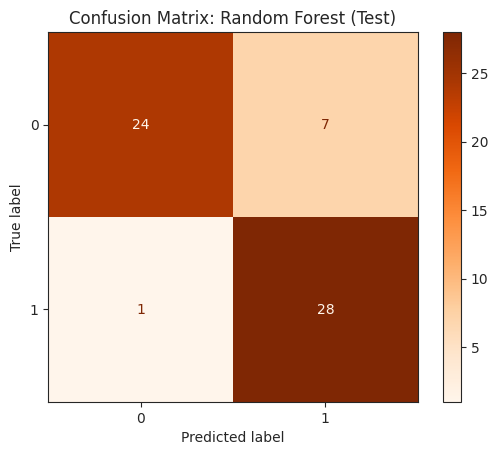

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred_lr, cmap='Oranges')
plt.title('Confusion Matrix: Random Forest (Test)')
plt.show()


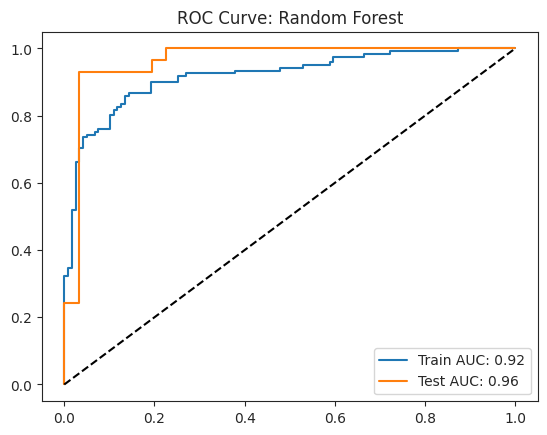

In [ ]:
fpr_tr_lr, tpr_tr_lr, _ = roc_curve(y_train, y_train_prob_lr)
fpr_ts_lr, tpr_ts_lr, _ = roc_curve(y_test, y_test_prob_lr)
plt.plot(fpr_tr_lr, tpr_tr_lr, label=f'Train AUC: {roc_auc_score(y_train, y_train_prob_lr):.2f}')
plt.plot(fpr_ts_lr, tpr_ts_lr, label=f'Test AUC: {roc_auc_score(y_test, y_test_prob_lr):.2f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('ROC Curve: Random Forest')
plt.legend()
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [ ]:
y_train_pred_rf = rf_model.predict(X_train)
y_test_pred_rf = rf_model.predict(X_test)


y_train_prob_rf = rf_model.predict_proba(X_train)[:, 1]
y_test_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("--- Random Forest Metrics (Test Set) ---")
print(f"Accuracy:  {accuracy_score(y_test, y_test_pred_rf):.4f}")
print(f"Precision: {precision_score(y_test, y_test_pred_rf):.4f}")
print(f"Recall:    {recall_score(y_test, y_test_pred_rf):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_test_pred_rf):.4f}")
print(f"AUC-ROC:   {roc_auc_score(y_test, y_test_prob_rf):.4f}")


--- Random Forest Metrics (Test Set) ---
Accuracy:  0.8667
Precision: 0.8000
Recall:    0.9655
F1 Score:  0.8750
AUC-ROC:   0.9700


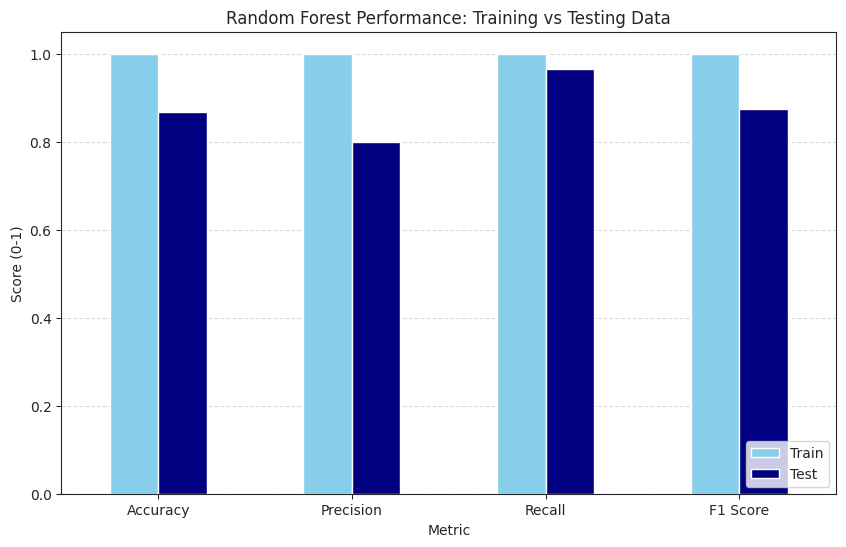

In [ ]:
rf_metrics_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    'Train': [accuracy_score(y_train, y_train_pred_rf),
              precision_score(y_train, y_train_pred_rf),
              recall_score(y_train, y_train_pred_rf),
              f1_score(y_train, y_train_pred_rf)],
    'Test': [accuracy_score(y_test, y_test_pred_rf),
             precision_score(y_test, y_test_pred_rf),
             recall_score(y_test, y_test_pred_rf),
             f1_score(y_test, y_test_pred_rf)]
})

rf_metrics_df.set_index('Metric').plot(kind='bar', figsize=(10, 6), color=['skyblue', 'navy'])
plt.title('Random Forest Performance: Training vs Testing Data')
plt.ylabel('Score (0-1)')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

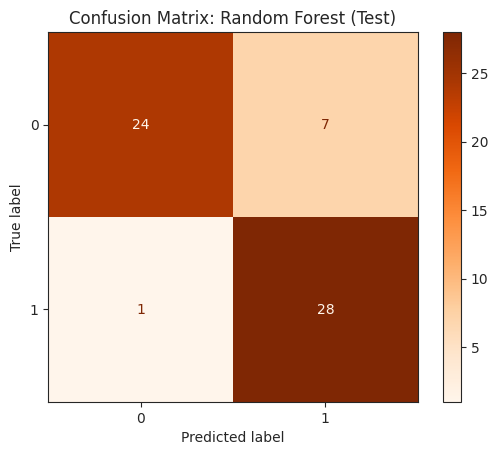

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred_rf, cmap='Oranges')
plt.title('Confusion Matrix: Random Forest (Test)')
plt.show()

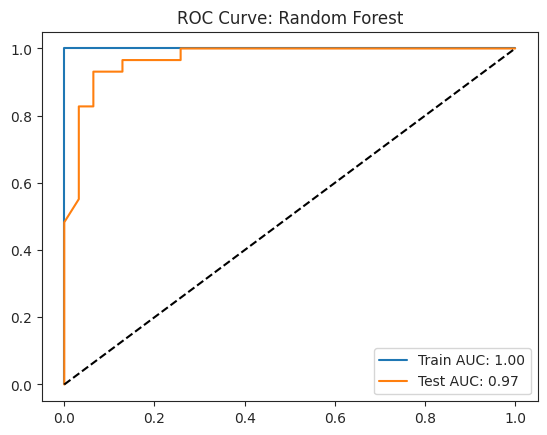

In [ ]:
fpr_tr_rf, tpr_tr_rf, _ = roc_curve(y_train, y_train_prob_rf)
fpr_ts_rf, tpr_ts_rf, _ = roc_curve(y_test, y_test_prob_rf)
plt.plot(fpr_tr_rf, tpr_tr_rf, label=f'Train AUC: {roc_auc_score(y_train, y_train_prob_rf):.2f}')
plt.plot(fpr_ts_rf, tpr_ts_rf, label=f'Test AUC: {roc_auc_score(y_test, y_test_prob_rf):.2f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('ROC Curve: Random Forest')
plt.legend()
plt.show()

In [ ]:
import pickle

#saving model three

with open('heart_model.pkl', 'wb') as file:
  pickle.dump(rf_model, file)

In [ ]:
import pickle

#saving model three

with open('heart_modelrg.pkl', 'wb') as file:
  pickle.dump(lr_model, file)

In [ ]:
import pickle

# Replace 'X_dummy' with the variable name you used
# right before scaling and PCA
model_columns = X_dummy.columns.tolist()

# Save it to a file
with open('model_columns.pkl', 'wb') as f:
    pickle.dump(model_columns, f)

print("File created successfully! Download it and upload it to your website folder.")


File created successfully! Download it and upload it to your website folder.


In [ ]:
import pickle

# Save the Scaler (expects 9 inputs)
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler_pca, f)

# Save the PCA (converts 9 inputs into 8 components)
with open('pca.pkl', 'wb') as f:
    pickle.dump(pca, f)

print("All 2026 deployment artifacts have been created.")


All 2026 deployment artifacts have been created.
